# 08 图像分割：从像素标签到小型 U-Net

分类为整图输出类别，检测为目标输出框，分割为**每个像素**输出类别。本课用圆形/矩形的合成数据训练真正的编码器—解码器网络。
输入 `[N,3,32,32]`，输出 logits `[N,3,32,32]`；标签 `[N,32,32]`，类别为背景、圆形、矩形。
默认 CPU 运行，无需下载。数据简单，适合观察流程，不能当作真实场景性能。


In [1]:
from pathlib import Path
import sys, os
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "course_utils.py").exists():
        sys.path.insert(0, str(folder)); break
else:
    raise FileNotFoundError("请从课程项目根目录或 notebooks 目录启动 Jupyter。")
from course_utils import setup, device, save_figure
ROOT = setup(seed=42)
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
from torch import nn
torch.set_num_threads(min(2, os.cpu_count() or 1))
DEVICE = device()
print("计算设备：", DEVICE)


计算设备： cuda


## 1. 输入图与真值掩膜一一对应

掩膜保存类别整数 0/1/2，不是彩色显示图。显示时使用色表，训练时仍使用原始整数。
先绘制圆再绘制矩形；重叠像素以矩形标签为准，这个规则对图像和掩膜完全一致。

图像采用 **NCHW**：`[N,3,32,32]` 依次为图片张数、RGB 通道、高、宽；浮点像素范围是 0–1。
掩膜采用 **NHW**：`[N,32,32]`，没有 RGB 通道；一个位置只保存一个类别编号，其中 `0=背景`、`1=圆形`、`2=矩形`。
因此打印的 8×8 掩膜局部矩阵中，每个整数对应一个像素的真值类别，不能把 `2` 理解成更亮的像素。


图像张量： (240, 3, 32, 32) 掩膜： (240, 32, 32)
目标边缘的掩膜局部矩阵：
 [[0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 2 2 2 2 2 2]
 [0 0 2 2 2 2 2 2]
 [0 0 2 2 2 2 2 2]
 [0 0 2 2 2 2 2 2]
 [0 0 2 2 2 2 2 2]
 [0 0 2 2 2 2 2 2]]


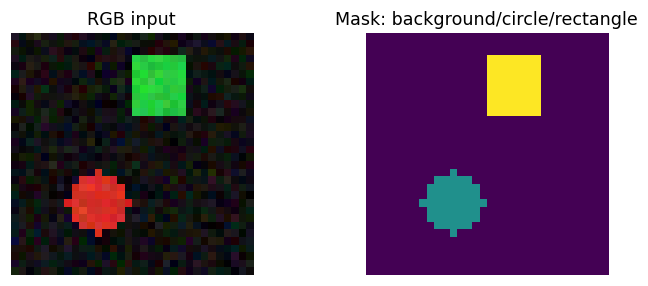

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/08_segmentation_inputs.png')

In [2]:
from torch.utils.data import DataLoader,TensorDataset
def make_segmentation_data(n,seed):
    rng=np.random.default_rng(seed); ims=[]; masks=[]
    for _ in range(n):
        im=rng.uniform(.02,.12,(32,32,3)).astype(np.float32); mask=np.zeros((32,32),np.uint8)
        x,y0=rng.integers(7,25,2); radius=int(rng.integers(4,7))
        cv2.circle(im,(int(x),int(y0)),radius,(.85,.18,.15),-1); cv2.circle(mask,(int(x),int(y0)),radius,1,-1)
        x,y0=rng.integers(2,20,2); w,h=rng.integers(6,12,2)
        cv2.rectangle(im,(int(x),int(y0)),(int(x+w),int(y0+h)),(.15,.8,.25),-1)
        cv2.rectangle(mask,(int(x),int(y0)),(int(x+w),int(y0+h)),2,-1)
        im=np.clip(im+rng.normal(0,.035,im.shape),0,1)
        ims.append(im.transpose(2,0,1)); masks.append(mask)
    return torch.tensor(np.array(ims),dtype=torch.float32),torch.tensor(np.array(masks),dtype=torch.long)
train_X,train_y=make_segmentation_data(240,10)
val_X,val_y=make_segmentation_data(60,20)
test_X,test_y=make_segmentation_data(60,30)
print("图像张量：",tuple(train_X.shape),"掩膜：",tuple(train_y.shape))
row,col=torch.nonzero(train_y[0],as_tuple=False)[0].tolist()
print("目标边缘的掩膜局部矩阵：\n",train_y[0,max(0,row-2):row+6,max(0,col-2):col+6].numpy())
fig,axs=plt.subplots(1,2,figsize=(8,3))
axs[0].imshow(train_X[0].permute(1,2,0)); axs[0].set_title("RGB input")
axs[1].imshow(train_y[0],cmap="viridis",vmin=0,vmax=2); axs[1].set_title("Mask: background/circle/rectangle")
for ax in axs: ax.axis("off")
save_figure("08_segmentation_inputs.png")


## 2. 一个带跳跃连接的小型 U-Net

编码器把分辨率从 32×32 降到 16×16，解码器上采样回原大小，并拼接浅层特征以恢复边界。
这是 U-Net 思想的极小教学版，不是原论文的完整配置。输出每个像素的三类 logits。

输出张量形状为 **NCHW** 的 `[N,3,32,32]`，但这里的 `C=3` 表示三个类别分数，含义与输入的 RGB 通道不同。
在固定像素 `(h,w)` 上，`logits[n,:,h,w]` 是背景/圆/矩形的三个分数；`argmax(dim=1)` 沿类别维取最大值，得到 `[N,32,32]` 的整数预测掩膜。
这个掩膜的形状和类别编号与真值完全一致，才能逐像素计算 Dice 和 IoU。


In [3]:
class MiniUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc=nn.Sequential(nn.Conv2d(3,8,3,padding=1),nn.ReLU(),nn.Conv2d(8,8,3,padding=1),nn.ReLU())
        self.low=nn.Sequential(nn.MaxPool2d(2),nn.Conv2d(8,16,3,padding=1),nn.ReLU(),nn.Conv2d(16,16,3,padding=1),nn.ReLU())
        self.dec=nn.Sequential(nn.Conv2d(24,8,3,padding=1),nn.ReLU(),nn.Conv2d(8,3,1))
    def forward(self,x):
        skip=self.enc(x); low=self.low(skip)
        up=nn.functional.interpolate(low,size=skip.shape[-2:],mode="bilinear",align_corners=False)
        return self.dec(torch.cat([skip,up],dim=1))
model=MiniUNet().to(DEVICE)
optimizer=torch.optim.Adam(model.parameters(),lr=.004)
loader=DataLoader(TensorDataset(train_X,train_y),batch_size=32,shuffle=True,num_workers=0)
print("模型输出：",tuple(model(train_X[:2].to(DEVICE)).shape))


模型输出： (2, 3, 32, 32)


## 3. 用验证集选择模型

像素级交叉熵直接接受 logits 和整数掩膜。训练准确率可能被大量背景像素抬高，因此选择模型时关注前景 Dice。
对每类 $c$，$Dice_c=2|P_c∩G_c|/(|P_c|+|G_c|)$，$IoU_c=|P_c∩G_c|/|P_c∪G_c|$。


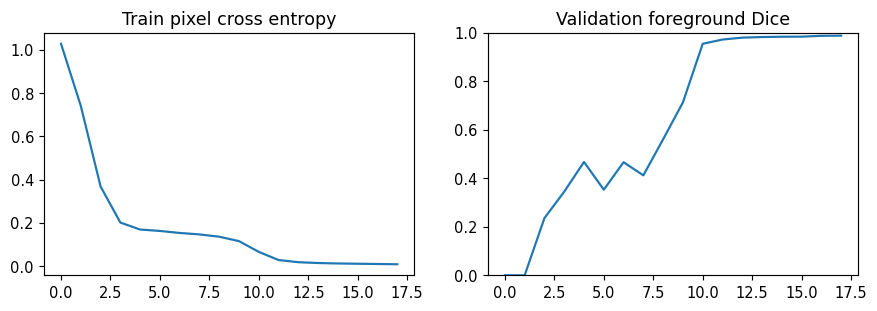

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/08_segmentation_training.png')

In [4]:
def segmentation_scores(pred,target):
    dice=[]; iou=[]
    for c in range(3):
        p=pred==c; g=target==c; inter=(p&g).sum().float()
        dice.append((2*inter/(p.sum()+g.sum()).clamp(min=1)).item())
        iou.append((inter/(p|g).sum().clamp(min=1)).item())
    return np.array(dice),np.array(iou)
import copy
history=[]; best=-1.; best_state=None
for epoch in range(18):
    model.train(); loss_sum=0.
    for xb,yb in loader:
        xb,yb=xb.to(DEVICE),yb.to(DEVICE)
        loss=nn.functional.cross_entropy(model(xb),yb)
        optimizer.zero_grad(); loss.backward(); optimizer.step(); loss_sum+=loss.item()*len(xb)
    model.eval()
    with torch.no_grad():
        val_pred=model(val_X.to(DEVICE)).argmax(1).cpu()
    val_dice,_=segmentation_scores(val_pred,val_y); score=val_dice[1:].mean()
    history.append((loss_sum/len(train_X),score))
    if score>best: best=score; best_state=copy.deepcopy(model.state_dict())
model.load_state_dict(best_state)
fig,axs=plt.subplots(1,2,figsize=(10,3))
axs[0].plot(np.array(history)[:,0]); axs[0].set_title("Train pixel cross entropy")
axs[1].plot(np.array(history)[:,1]); axs[1].set_title("Validation foreground Dice"); axs[1].set_ylim(0,1)
save_figure("08_segmentation_training.png")


## 4. 测试掩膜、叠加图与指标

测试集从未参与拟合或模型选择。图中同一列展示同一输入的真值、预测和叠加，便于查看边界错位。
本例是语义分割：两个相同类别的圆不会自动得到独立 ID；实例分割还要区分个体。


各类 Dice [背景,圆,矩形]： [0.999 0.984 0.997]
各类 IoU： [0.998 0.969 0.993] mIoU(含背景)= 0.987
预测掩膜局部：
 [[0 2 2 2 2 2 2 2]
 [0 2 2 2 2 2 2 2]
 [0 2 2 2 2 2 2 2]
 [0 0 0 0 0 0 1 1]
 [0 0 0 0 0 0 1 1]
 [0 0 0 0 0 0 1 1]
 [0 0 0 0 0 0 1 1]
 [0 0 0 0 0 0 1 1]]


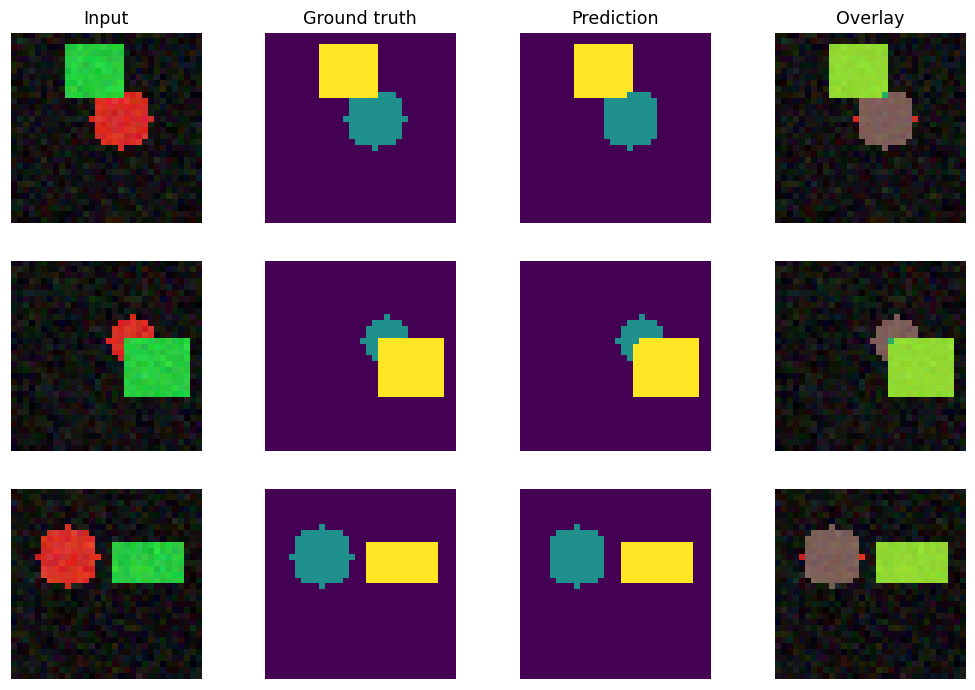

In [5]:
model.eval()
with torch.no_grad():
    pred=model(test_X.to(DEVICE)).argmax(1).cpu()
dice,iou=segmentation_scores(pred,test_y)
print("各类 Dice [背景,圆,矩形]：",np.round(dice,3))
print("各类 IoU：",np.round(iou,3),"mIoU(含背景)=",round(iou.mean(),3))
print("预测掩膜局部：\n",pred[0,8:16,8:16].numpy())
fig,axs=plt.subplots(3,4,figsize=(12,8))
for i in range(3):
    rgb=test_X[i].permute(1,2,0).numpy()
    axs[i,0].imshow(rgb); axs[i,1].imshow(test_y[i],vmin=0,vmax=2,cmap="viridis")
    axs[i,2].imshow(pred[i],vmin=0,vmax=2,cmap="viridis")
    axs[i,3].imshow(rgb); axs[i,3].imshow(np.ma.masked_where(pred[i]==0,pred[i]),vmin=0,vmax=2,cmap="viridis",alpha=.5)
for ax,title in zip(axs[0],["Input","Ground truth","Prediction","Overlay"]): ax.set_title(title)
for ax in axs.flat: ax.axis("off")
save_figure("08_segmentation_results.png")
assert dice[1:].mean()>.85,"前景分割效果异常，请检查训练和标签。"


## 5. 检查颜色捷径与失败情况

训练中的颜色与类别关联，网络可能学到颜色捷径。将红绿通道互换，相同几何物体仍应保持原类别；若预测改变，说明模型对颜色依赖很强。
这个实验用来揭示局限，不把合成数据上的高分宣传为真实泛化能力。


颜色变化前前景 Dice： 0.99 变化后： 0.005


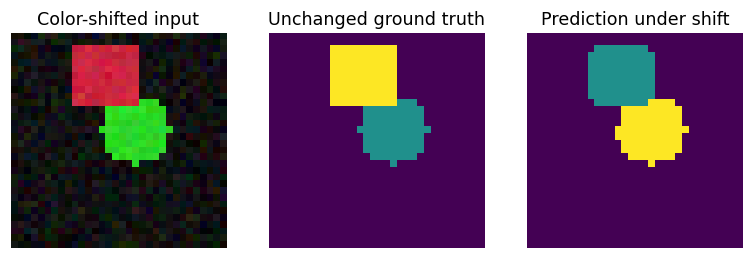

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/08_segmentation_domain_shift.png')

In [6]:
shifted=test_X[:,[1,0,2]].clone()
with torch.no_grad(): shifted_pred=model(shifted.to(DEVICE)).argmax(1).cpu()
shifted_dice,_=segmentation_scores(shifted_pred,test_y)
print("颜色变化前前景 Dice：",round(dice[1:].mean(),3),"变化后：",round(shifted_dice[1:].mean(),3))
fig,axs=plt.subplots(1,3,figsize=(9,3))
axs[0].imshow(shifted[0].permute(1,2,0)); axs[0].set_title("Color-shifted input")
axs[1].imshow(test_y[0],vmin=0,vmax=2); axs[1].set_title("Unchanged ground truth")
axs[2].imshow(shifted_pred[0],vmin=0,vmax=2); axs[2].set_title("Prediction under shift")
for ax in axs: ax.axis("off")
save_figure("08_segmentation_domain_shift.png")


## 6. 练习与参考

练习：让每类拥有多种颜色，重新训练，比较颜色变化实验；改变掩膜尺寸后使用最近邻插值（不要用双线性插值生成非整数标签）；增加实例 ID，分析语义与实例分割的区别。

来源：[U-Net 原论文](https://arxiv.org/abs/1505.04597)、[PyTorch 像素交叉熵](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)、[TorchVision 分割模型](https://pytorch.org/vision/stable/models.html#semantic-segmentation)。
